In [1]:
import numpy as np
import math
import qutip as qt
import time
import warnings
warnings.filterwarnings('ignore')

# ========= 1. 参数设置 =========
N_dim = 60
kappa_val = 1.0

# 时间尺度设置
T_MAX_COMP = 1.5     # 复杂度演化到 1.5
T_MAX_FIDE = 0.02    # 保真度演化到 0.02

tau_list_comp = np.linspace(0.0, T_MAX_COMP, 80)
tau_list_fide = np.linspace(0.0, T_MAX_FIDE, 40)

# Even猫态催化参数配置
plot_cases = [(0, 2), (1, 2)]

state_configs = {
    (0, 2): {'g': 1.01, 'alpha_in': 1.97, 'alpha_out': 3.46, 'r_c': 0.26, 'target_cat_type': 'even'},
    (1, 2): {'g': 1.05, 'alpha_in': 1.18, 'alpha_out': 2.02, 'r_c': 0.23, 'target_cat_type': 'odd'}
}

# ========= 2. 核心算法函数 =========
def generate_input_cat(dim, alpha, cat_type='even'):
    """生成初始猫态"""
    alpha_state = qt.coherent(dim, alpha)
    minus_alpha_state = qt.coherent(dim, -alpha)
    if cat_type == 'even':
        return (alpha_state + minus_alpha_state).unit()
    else:
        return (alpha_state - minus_alpha_state).unit()

def generate_catalyzed_state(m, n, g, phi_in, dim):
    """通用的 (m,n) 阶催化操作"""
    if g <= 1.0:
        return None
        
    G = np.sqrt(1 - 1 / (g**2)) 
    a_op = qt.destroy(dim)
    adag = a_op.dag()
    g_op = qt.Qobj(np.diag([g**(-j) for j in range(dim)]))
    
    psi_out = qt.basis(dim, 0) * 0.0
    for k in range(m + 1):
        if n - m + k < 0: 
            continue
        num = ((-1)**(n - m + k)) * (G**(n - m + 2 * k)) * math.sqrt(math.factorial(n) * math.factorial(m))
        den = (g**(m - k + 1)) * math.factorial(k) * math.factorial(n - m + k) * math.factorial(m - k)
        coef = num / den
        psi_out += coef * (adag**(n - m + k)) * g_op * (a_op**k) * phi_in
        
    return psi_out.unit()

def generate_target_cat(dim, alpha, r_c, cat_type='even'):
    """生成用于计算保真度的目标压缩猫态"""
    cat = generate_input_cat(dim, alpha, cat_type)
    return (qt.squeeze(dim, r_c) * cat).unit()

def get_complexity_val(rho, limit=12.0, pts=300):
    """计算量子态复杂度 C"""
    xvec = np.linspace(-limit, limit, pts)
    yvec = np.linspace(-limit, limit, pts)
    Q = qt.qfunc(rho, xvec, yvec)
    mask = Q > 1e-15  
    dx, dy = xvec[1]-xvec[0], yvec[1]-yvec[0]
    Sw_val = -np.sum(Q[mask] * np.log(np.pi * Q[mask])) * dx * dy
    dQ_dy, dQ_dx = np.gradient(Q, dy, dx)
    I_val = 0.25 * np.sum((dQ_dx**2 + dQ_dy**2)[mask] / Q[mask]) * dx * dy
    return np.exp(Sw_val - 1.0) * I_val

# ========= 3. 演化与数据收集 =========
if __name__ == "__main__":
    start_time = time.time()
    print("🚀 开始计算 Even 输入的右图复杂度演化数据...")

    save_dict = {
        'tau_list_comp': tau_list_comp,
        'tau_list_fide': tau_list_fide,
        'T_MAX_COMP': T_MAX_COMP,
        'T_MAX_FIDE': T_MAX_FIDE
    }

    for m, n in plot_cases:
        cfg = state_configs[(m, n)]
        
        print(f"\n▶ 正在计算 m={m}, n={n} ...")
        
        # 输入设为偶猫态 'even'
        psi_init_cat = generate_input_cat(N_dim, cfg['alpha_in'], 'even')
        psi_out = generate_catalyzed_state(m, n, cfg['g'], psi_init_cat, N_dim)
        rho_init = qt.ket2dm(psi_out)
        
        # 目标态根据表格配置奇偶性
        psi_target = generate_target_cat(N_dim, cfg['alpha_out'], cfg['r_c'], cfg['target_cat_type'])
        
        a_op = qt.destroy(N_dim)
        c_ops = [np.sqrt(2 * kappa_val) * a_op]
        
        me_comp = qt.mesolve(0*a_op, rho_init, tau_list_comp/kappa_val, c_ops)
        me_fide = qt.mesolve(0*a_op, rho_init, tau_list_fide/kappa_val, c_ops)
        
        comp_vols = []
        for idx, r in enumerate(me_comp.states):
            comp_vols.append(get_complexity_val(r))
            if (idx+1) % 10 == 0:
                print(f"  └ 复杂度计算进度: {idx+1}/{len(tau_list_comp)}")
                
        save_dict[f'comp_{m}_{n}'] = comp_vols
        save_dict[f'fide_{m}_{n}'] = [qt.fidelity(r, psi_target)**2 for r in me_fide.states]

    # 保存为 Even 专属复杂度文件
    np.savez('comp_fide_data_even.npz', **save_dict)
    print(f"\n✅ 数据计算完成！耗时: {time.time() - start_time:.2f} 秒")
    print("数据已成功保存至 'comp_fide_data_even.npz'")

🚀 开始计算 Even 输入的右图复杂度演化数据...

▶ 正在计算 m=0, n=2 ...
  └ 复杂度计算进度: 10/80
  └ 复杂度计算进度: 20/80
  └ 复杂度计算进度: 30/80
  └ 复杂度计算进度: 40/80
  └ 复杂度计算进度: 50/80
  └ 复杂度计算进度: 60/80
  └ 复杂度计算进度: 70/80
  └ 复杂度计算进度: 80/80

▶ 正在计算 m=1, n=2 ...
  └ 复杂度计算进度: 10/80
  └ 复杂度计算进度: 20/80
  └ 复杂度计算进度: 30/80
  └ 复杂度计算进度: 40/80
  └ 复杂度计算进度: 50/80
  └ 复杂度计算进度: 60/80
  └ 复杂度计算进度: 70/80
  └ 复杂度计算进度: 80/80

✅ 数据计算完成！耗时: 78.91 秒
数据已成功保存至 'comp_fide_data_even.npz'


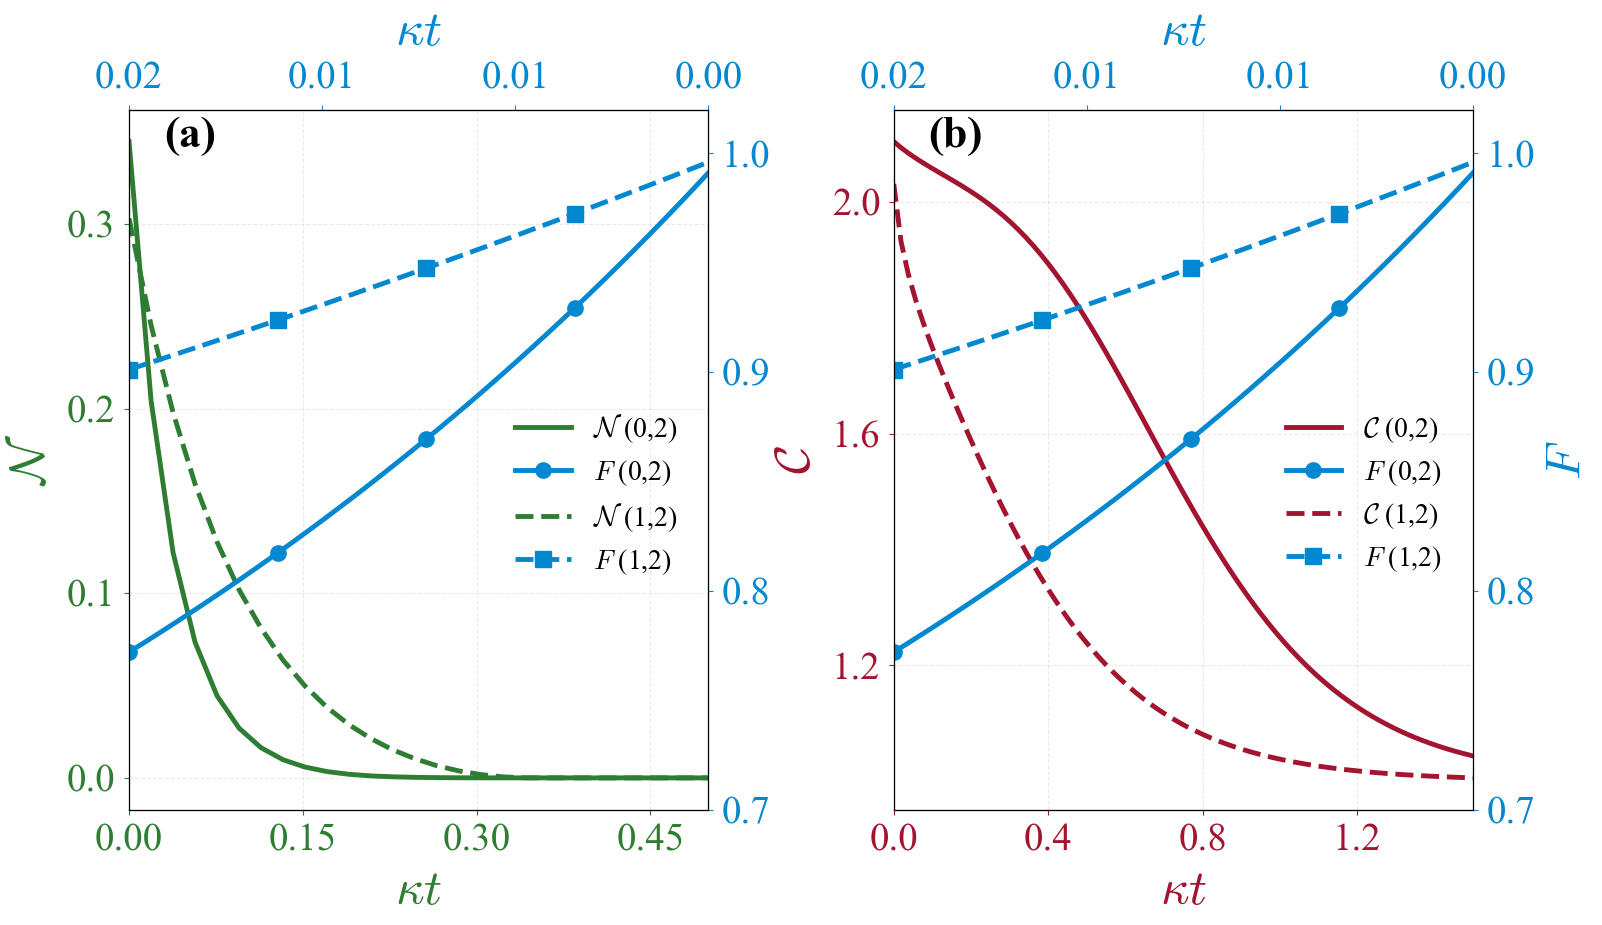

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.ticker import MaxNLocator
import warnings
warnings.filterwarnings('ignore')

# =====================================================================
# 1. 字号配置与图例位置调节参数 (针对 8cm 双栏印刷宽度极限优化)
# =====================================================================
FIG_SIZE = (16, 10)
LABEL_SIZE = 36              # 坐标轴标题字体大小
TICK_SIZE = 28               # 坐标轴数字刻度字体大小
SUBPLOT_LABEL_SIZE = 32      # 角标 (a) (b) 文本大小
LEGEND_SIZE = 22             # 图例字体大小
LINE_WIDTH = 3.5             # 线条宽度
MARKER_SIZE = 11             # Marker大小

# 🌟 图例位置微调参数 (基于各自子图的比例坐标，0~1之间) 🌟
# 修改这里即可自行上下左右移动图例：(水平位置, 垂直位置)
LEGEND_POS_A = (0.99, 0.45)  # 图(a)的图例锚点
LEGEND_POS_B = (0.99, 0.45)  # 图(b)的图例锚点

plt.style.use('seaborn-v0_8-muted')
mpl.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'mathtext.fontset': 'cm',
    'axes.labelsize': LABEL_SIZE,
    'xtick.labelsize': TICK_SIZE,
    'ytick.labelsize': TICK_SIZE,
    'legend.fontsize': LEGEND_SIZE,
    'text.usetex': False
})

# =====================================================================
# 2. 读取两个文件的保存数据 (提取 Even cat state 数据)
# =====================================================================
try:
    data_a = np.load('wigner_fide_data_even.npz')
    tau_list_neg = data_a['tau_list_neg']
    tau_list_fide_a = data_a['tau_list_fide']
    t_max_neg = float(data_a['t_max_neg'])
    t_max_fide_a = float(data_a['t_max_fide'])

    data_b = np.load('comp_fide_data_even.npz')
    tau_list_comp = data_b['tau_list_comp']
    tau_list_fide_b = data_b['tau_list_fide']
    t_max_comp = float(data_b['T_MAX_COMP'])
    t_max_fide_b = float(data_b['T_MAX_FIDE'])
except FileNotFoundError:
    print("错误：找不到对应的 npz 数据文件，请确认均已计算完毕。")
    exit()

plot_cases = [(0, 2), (1, 2)]
line_styles = ['-', '--']
point_markers = ['o', 's']

# =====================================================================
# 3. 1x2 双子图绘制逻辑
# =====================================================================
fig, (ax_neg, ax_comp) = plt.subplots(1, 2, figsize=FIG_SIZE)

# 图(a) 双轴框架（保留右侧和上侧蓝色保真度边框与刻度）
ax_fide_a = ax_neg.twinx()
ax_top_a  = ax_neg.twiny()

# 图(b) 双轴框架（复杂度与保真度）
ax_fide_b = ax_comp.twinx()
ax_top_b  = ax_comp.twiny()

color_neg  = '#2E7D32'   # 绿色 - 负体积
color_comp = '#A2142F'   # 红色 - 复杂度
color_fide = '#0288D1'   # 蓝色 - 保真度

# =====================================================================
# --- 图 (a): 左侧 - Negativity (绿色)  ---
# =====================================================================
# 独立设置图a的绘制范围
t_max_neg_a = 0.5 

ax_neg.set_xlim(0, t_max_neg_a)
ax_neg.set_xlabel(r'$\kappa t$', color=color_neg, labelpad=8)
ax_neg.set_ylabel(r'$\mathcal{N}$', color=color_neg, labelpad=8)
ax_neg.tick_params(axis='x', colors=color_neg, pad=6)
ax_neg.tick_params(axis='y', colors=color_neg, pad=6)
ax_neg.spines['bottom'].set_color(color_neg)
ax_neg.spines['left'].set_color(color_neg)
ax_neg.xaxis.set_major_locator(MaxNLocator(nbins=4))
ax_neg.yaxis.set_major_locator(MaxNLocator(nbins=4))

ax_fide_a.set_ylim(0.7, 1.02)
ax_fide_a.tick_params(axis='y', colors=color_fide, pad=6)
ax_fide_a.spines['right'].set_color(color_fide)
ax_fide_a.yaxis.set_major_locator(MaxNLocator(nbins=4))

# 顶部 F 轴依然显示 4 个点，映射至新的宽度 t_max_neg_a
ax_top_a.set_xlim(0, t_max_neg_a)
ax_top_a.set_xticks(np.linspace(0, t_max_neg_a, 4))
ax_top_a.set_xticklabels([f'{x:.2f}' for x in np.linspace(t_max_fide_a, 0, 4)])
ax_top_a.set_xlabel(r'$\kappa t$', color=color_fide, labelpad=12)
ax_top_a.tick_params(axis='x', colors=color_fide, pad=6)
ax_top_a.spines['top'].set_color('black')

lines_a = []
for idx, (m, n) in enumerate(plot_cases):
    neg_data = data_a[f'neg_{m}_{n}']
    fide_data = data_a[f'fide_{m}_{n}']
    
    # N 曲线依然使用原数据，ax_neg.set_xlim会自动截取0~0.5部分
    ln_n, = ax_neg.plot(tau_list_neg, neg_data, color=color_neg, 
                        ls=line_styles[idx], lw=LINE_WIDTH, label=rf'$\mathcal{{N}}$ ({m},{n})')
    
    # F 曲线映射基准更新为 t_max_neg_a，确保 F 的视觉跨度保持全图铺满不变
    tau_mapped_a = (tau_list_fide_a / t_max_fide_a) * t_max_neg_a
    lf_a, = ax_fide_a.plot(tau_mapped_a, fide_data[::-1], color=color_fide,
                           ls=line_styles[idx], marker=point_markers[idx], 
                           ms=MARKER_SIZE, markevery=10, lw=LINE_WIDTH, label=rf'$F$ ({m},{n})')
    # 提取所有线段，不再使用[::2]跳过蓝线
    lines_a.extend([ln_n, lf_a])

ax_neg.grid(True, ls='--', alpha=0.25)

# 【核心修改】：提取全部曲线，竖直排列(ncol=1)，绝对坐标控制位置
ax_neg.legend(lines_a, [l.get_label() for l in lines_a], 
              loc='center right', bbox_to_anchor=LEGEND_POS_A, 
              frameon=False, fontsize=LEGEND_SIZE-2, ncol=1)

# 删除 bbox 字典，背景全透明
ax_neg.text(0.06, 0.99, '(a)', transform=ax_neg.transAxes, 
            fontsize=SUBPLOT_LABEL_SIZE, fontweight='bold', verticalalignment='top', horizontalalignment='left')

# -----------------------------------------
# --- 图 (b): 右侧 - C (红色) & F (蓝色) ---
# -----------------------------------------
ax_comp.set_xlim(0, t_max_comp)
ax_comp.set_xlabel(r'$\kappa t$', color=color_comp, labelpad=8)
ax_comp.set_ylabel(r'$\mathcal{C}$', color=color_comp, labelpad=8)
ax_comp.tick_params(axis='x', colors=color_comp, pad=6)
ax_comp.tick_params(axis='y', colors=color_comp, pad=6)
ax_comp.spines['bottom'].set_color(color_comp)
ax_comp.spines['left'].set_color(color_comp)
ax_comp.xaxis.set_major_locator(MaxNLocator(nbins=4))
ax_comp.yaxis.set_major_locator(MaxNLocator(nbins=4))

ax_fide_b.set_ylim(0.7, 1.02)
ax_fide_b.set_ylabel(r'$F$', color=color_fide, labelpad=8)
ax_fide_b.tick_params(axis='y', colors=color_fide, pad=6)
ax_fide_b.spines['right'].set_color(color_fide)
ax_fide_b.yaxis.set_major_locator(MaxNLocator(nbins=4))

ax_top_b.set_xlim(0, t_max_comp)
ax_top_b.set_xticks(np.linspace(0, t_max_comp, 4))
ax_top_b.set_xticklabels([f'{x:.2f}' for x in np.linspace(t_max_fide_b, 0, 4)])
ax_top_b.set_xlabel(r'$\kappa t$', color=color_fide, labelpad=12)
ax_top_b.tick_params(axis='x', colors=color_fide, pad=6)
ax_top_b.spines['top'].set_color('black')

lines_b = []
for idx, (m, n) in enumerate(plot_cases):
    comp_data = data_b[f'comp_{m}_{n}']
    fide_data = data_b[f'fide_{n}'] if 'fide_' + str(n) in data_b.files else data_b[f'fide_{m}_{n}']
    
    ln_c, = ax_comp.plot(tau_list_comp, comp_data, color=color_comp, 
                         ls=line_styles[idx], lw=LINE_WIDTH, label=rf'$\mathcal{{C}}$ ({m},{n})')
    
    tau_mapped_b = (tau_list_fide_b / t_max_fide_b) * t_max_comp
    lf_b, = ax_fide_b.plot(tau_mapped_b, fide_data[::-1], color=color_fide, 
                         ls=line_styles[idx], marker=point_markers[idx], 
                         ms=MARKER_SIZE, markevery=10, lw=LINE_WIDTH, label=rf'$F$ ({m},{n})')
    # 提取所有线段，不再使用[::2]跳过蓝线
    lines_b.extend([ln_c, lf_b])

ax_comp.grid(True, ls='--', alpha=0.25)

# 【核心修改】：提取全部曲线，竖直排列(ncol=1)，绝对坐标控制位置
ax_comp.legend(lines_b, [l.get_label() for l in lines_b], 
               loc='center right', bbox_to_anchor=LEGEND_POS_B, 
               frameon=False, fontsize=LEGEND_SIZE-2, ncol=1)

# 删除 bbox 字典，背景全透明
ax_comp.text(0.06, 0.99, '(b)', transform=ax_comp.transAxes, 
             fontsize=SUBPLOT_LABEL_SIZE, fontweight='bold', verticalalignment='top', horizontalalignment='left')

# =====================================================================
# 4. 排版间距微调
# =====================================================================
plt.subplots_adjust(left=0.08, right=0.92, bottom=0.15, top=0.85, wspace=0.32)

plt.savefig('combined_1x2_even_cat_N_and_C.png', dpi=400, bbox_inches='tight')
plt.show()

In [7]:
import numpy as np

def find_target_time_even(target_f=0.9):
    # 读取 even 对应的保存文件
    file_name = 'wigner_fide_data_even.npz' 
    cases = [(0, 2), (1, 2)]  # Even 对应的两种情况
    
    try:
        data = np.load(file_name)
        tau_list = data['tau_list_fide']
        
        print(f"🎯 正在从 {file_name} 中寻找保真度 F={target_f} 对应的 \u03bat 时刻...\n")
        
        for m, n in cases:
            fide = data[f'fide_{m}_{n}']
            
            # 检查 0.9 是否在当前数据的数值范围内
            if np.min(fide) <= target_f <= np.max(fide):
                # numpy.interp 要求横坐标序列是单调递增的，所以我们将随时间衰减的 F 和 tau 倒序排列
                fide_rev = fide[::-1]
                tau_rev = tau_list[::-1]
                
                # 以保真度为横轴，时间为纵轴进行插值
                t_target = np.interp(target_f, fide_rev, tau_rev)
                print(f" ✅ 状态 (m={m}, n={n}) [Even]: \u03bat ≈ {t_target:.5f}")
            else:
                print(f" ⚠️ 状态 (m={m}, n={n}) [Even]: 数据未跨越 {target_f} (当前极值范围: {np.min(fide):.4f} ~ {np.max(fide):.4f})")
                
    except FileNotFoundError:
        print(f"找不到 {file_name}，请确认在同一文件夹下（也可尝试改为 'comp_fide_data_even.npz'）。")

if __name__ == "__main__":
    find_target_time_even(0.9)

🎯 正在从 wigner_fide_data_even.npz 中寻找保真度 F=0.9 对应的 κt 时刻...

 ✅ 状态 (m=0, n=2) [Even]: κt ≈ 0.00704
 ⚠️ 状态 (m=1, n=2) [Even]: 数据未跨越 0.9 (当前极值范围: 0.9012 ~ 0.9960)
